# 冠军模型：Drogue attached / lost 是否影响预测误差？

本 Notebook 使用同一批 **757 个 held-out test cases**，比较四个已经确定的冠军模型。模型不再调参，也不使用 test set 重新训练。

分析分两层：
1. 描述性比较：attached 与 lost 的 72-h median error、RMSE、ITE；
2. 调整后比较：控制 ocean regime、GLORYS climatological current speed、水深和 forecast-origin speed，并按 drifter ID 做 cluster bootstrap。

> 这仍然是观察性分析。即使差异显著，也只能说 drogue status 与误差相关，不能直接解释为 drogue 脱落导致误差增加。

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data'/'processed'/'forecast_origins.parquet').exists()),None)
if ROOT is None: raise FileNotFoundError('请从 data3001-project 或其子目录运行。')
OUT=ROOT/'output'/'rq1'/'zh'
FIG=OUT/'drogue_champion_analysis'
FIG.mkdir(parents=True,exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False})
print('Project:',ROOT)

Matplotlib is building the font cache; this may take a moment.


Project: /Users/roger/Documents/data3001-project


## 1. 合并四个冠军模型的 test-case 误差与环境标签

In [2]:
origins=pd.read_parquet(ROOT/'data'/'processed'/'forecast_origins.parquet')
origins=origins.loc[origins.partition.eq('test')].copy()
regimes=pd.read_csv(ROOT/'RQ2'/'data'/'forecast_case_regimes.csv')
regimes=regimes[['forecast_case_id','regime','depth_m','current_speed_clim']]

files={
 'Optimised FNN':'optimised_fnn_test_case_metrics.csv',
 'Boosting residual':'boosting_residual_test_case_metrics.csv',
 'Optimised Weighted KNN':'optimised_knn_test_case_metrics.csv',
 'Optimised Random Forest':'optimised_random_forest_test_case_metrics.csv',
}
parts=[]
for model,fn in files.items():
    d=pd.read_csv(OUT/fn).rename(columns={'ID':'drifter_id','final_72h_error_km':'error_72h_km','integrated_trajectory_error_km_h':'ite_km_h'})
    d=d[['forecast_case_id','drifter_id','error_72h_km','ite_km_h']].copy(); d['model']=model; parts.append(d)
errors=pd.concat(parts,ignore_index=True)
meta=origins[['forecast_case_id','ID','drogue_status_at_origin','origin_ve','origin_vn']].merge(regimes,on='forecast_case_id',how='left',validate='one_to_one')
meta['origin_speed_m_s']=np.hypot(meta.origin_ve,meta.origin_vn)
data=errors.merge(meta,on='forecast_case_id',how='left',validate='many_to_one')
data['drogue_status']=data.drogue_status_at_origin.replace({'attached':'Attached','lost':'Lost'})
assert data.groupby('model').size().eq(757).all()
display(data.groupby(['model','drogue_status']).agg(cases=('forecast_case_id','size'),drifters=('drifter_id','nunique')).reset_index())

,model,drogue_status,cases,drifters
0,Boosting residual,Attached,502,51
1,Boosting residual,Lost,255,36
2,Optimised FNN,Attached,502,51
3,Optimised FNN,Lost,255,36
4,Optimised Random Forest,Attached,502,51
5,Optimised Random Forest,Lost,255,36
6,Optimised Weighted KNN,Attached,502,51
7,Optimised Weighted KNN,Lost,255,36


## 2. 未调整的误差比较

,model,drogue_status,n_cases,n_drifters,median_72h_error_km,rmse_72h_km,p90_72h_error_km,median_ite_km_h
0,Boosting residual,Attached,502,51,38.275,56.950,91.363,1326.036
1,Boosting residual,Lost,255,36,47.468,67.655,108.676,1686.183
2,Optimised FNN,Attached,502,51,37.931,58.075,91.178,1308.943
3,Optimised FNN,Lost,255,36,46.910,68.260,107.486,1580.174
4,Optimised Random Forest,Attached,502,51,38.869,58.288,89.886,1321.351
5,Optimised Random Forest,Lost,255,36,47.155,69.186,107.745,1645.070
6,Optimised Weighted KNN,Attached,502,51,37.811,59.771,96.045,1313.536
7,Optimised Weighted KNN,Lost,255,36,47.509,70.822,113.595,1626.580


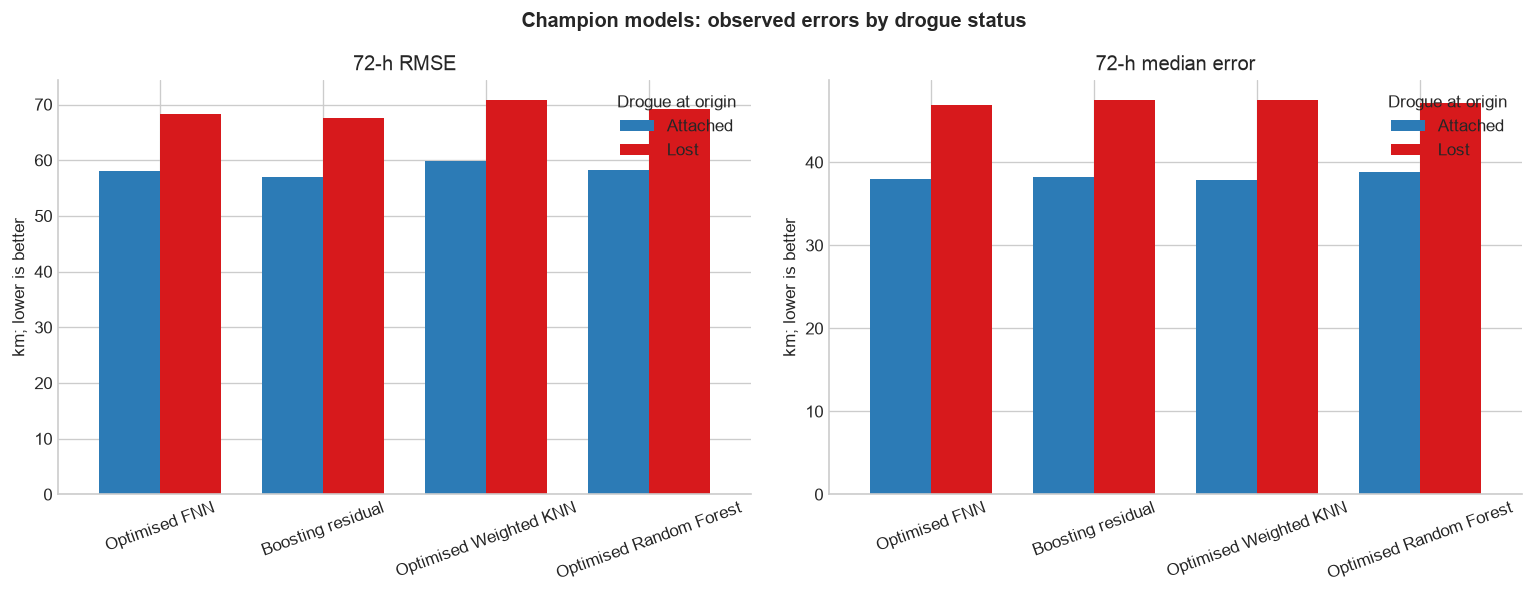

In [3]:
summary=(data.groupby(['model','drogue_status']).agg(
    n_cases=('forecast_case_id','size'),n_drifters=('drifter_id','nunique'),
    median_72h_error_km=('error_72h_km','median'),
    rmse_72h_km=('error_72h_km',lambda x: np.sqrt(np.mean(np.square(x)))),
    p90_72h_error_km=('error_72h_km',lambda x: np.quantile(x,.9)),
    median_ite_km_h=('ite_km_h','median')).reset_index())
display(summary.round(3))

order=list(files)
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,metric,title in [(axes[0],'rmse_72h_km','72-h RMSE'),(axes[1],'median_72h_error_km','72-h median error')]:
    p=summary.pivot(index='model',columns='drogue_status',values=metric).reindex(order)
    p.plot.bar(ax=ax,color=['#2C7BB6','#D7191C'],width=.75)
    ax.set_title(title); ax.set_ylabel('km; lower is better'); ax.set_xlabel(''); ax.tick_params(axis='x',rotation=20); ax.legend(title='Drogue at origin',frameon=False)
fig.suptitle('Champion models: observed errors by drogue status',fontweight='bold'); fig.tight_layout()
fig.savefig(FIG/'drogue_status_descriptive_errors.png',dpi=200,bbox_inches='tight'); plt.show()

## 3. Drifter-cluster bootstrap

每次重抽完整 drifter，而不是把同一 drifter 的多个 forecast cases 当成独立样本。差值定义为 `Lost − Attached`；大于0表示 lost cases 误差更大。

In [4]:
def metric_difference(frame,metric):
    a=frame.loc[frame.drogue_status.eq('Attached'),metric].to_numpy(); l=frame.loc[frame.drogue_status.eq('Lost'),metric].to_numpy()
    if not len(a) or not len(l): return np.nan
    if metric=='error_72h_km': return np.sqrt(np.mean(l*l))-np.sqrt(np.mean(a*a))
    return np.median(l)-np.median(a)

def cluster_bootstrap_difference(frame,metric,n_boot=5000,seed=2026):
    groups={k:g for k,g in frame.groupby('drifter_id')}; ids=np.array(list(groups)); rng=np.random.default_rng(seed)
    point=metric_difference(frame,metric); draws=[]
    for _ in range(n_boot):
        sample=pd.concat([groups[i] for i in rng.choice(ids,len(ids),replace=True)],ignore_index=True)
        value=metric_difference(sample,metric)
        if np.isfinite(value): draws.append(value)
    lo,hi=np.quantile(draws,[.025,.975])
    return point,lo,hi,len(draws)

rows=[]
for model,g in data.groupby('model',sort=False):
    for metric,label in [('error_72h_km','RMSE difference'),('ite_km_h','Median ITE difference')]:
        point,lo,hi,n=cluster_bootstrap_difference(g,metric)
        rows.append({'model':model,'contrast':label,'lost_minus_attached':point,'ci_lower':lo,'ci_upper':hi,'bootstrap_draws':n,'ci_excludes_zero':bool(lo>0 or hi<0)})
bootstrap=pd.DataFrame(rows)
display(bootstrap.round(3))

,model,contrast,lost_minus_attached,ci_lower,ci_upper,bootstrap_draws,ci_excludes_zero
0,Optimised FNN,RMSE difference,10.185,-0.713,21.727,5000,False
1,Optimised FNN,Median ITE difference,271.231,41.199,488.574,5000,True
2,Boosting residual,RMSE difference,10.705,1.102,20.261,5000,True
3,Boosting residual,Median ITE difference,360.147,60.055,614.369,5000,True
4,Optimised Weighted KNN,RMSE difference,11.051,-0.902,23.106,5000,False
5,Optimised Weighted KNN,Median ITE difference,313.044,-31.708,658.943,5000,False
6,Optimised Random Forest,RMSE difference,10.898,-0.750,22.559,5000,False
7,Optimised Random Forest,Median ITE difference,323.719,-53.008,641.733,5000,False


## 4. 控制 regime、流速和水深后的关联

使用 `log(1 + 72-h error)` 作为响应。系数转换为百分比后表示：在相同 regime、climatological current speed、水深和 origin speed 条件下，lost cases 的典型误差相对 attached cases 改变多少。置信区间仍按 drifter cluster bootstrap 计算。

,model,adjusted_lost_error_change_pct,ci_lower_pct,ci_upper_pct,ci_excludes_zero
0,Optimised FNN,5.63,-10.12,20.65,False
1,Boosting residual,11.74,-3.97,27.26,False
2,Optimised Weighted KNN,14.10,-2.22,30.61,False
3,Optimised Random Forest,12.18,-5.12,29.17,False


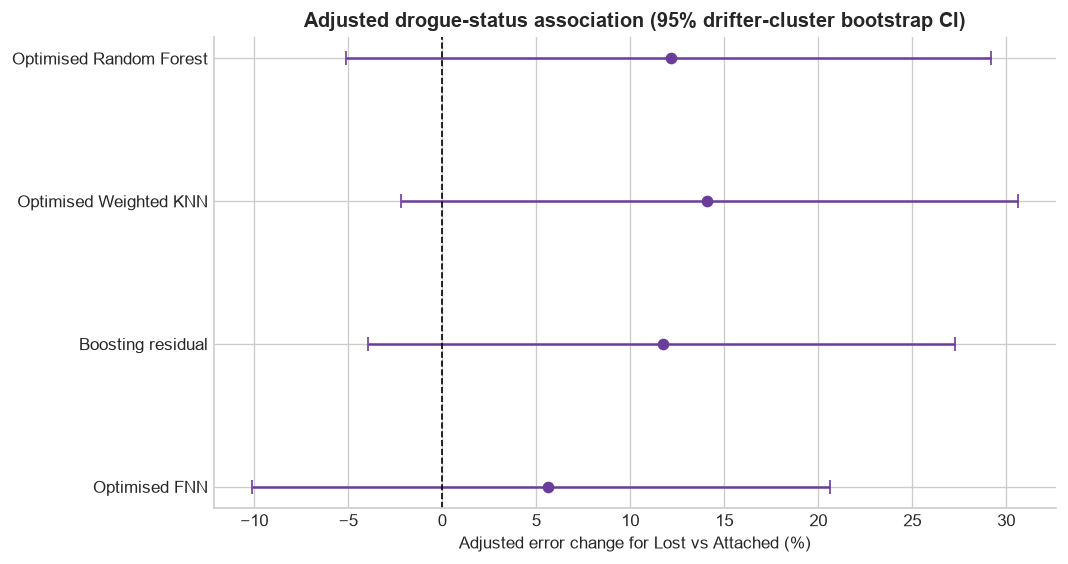

In [5]:
def design_matrix(frame):
    z=frame.copy()
    continuous=z[['current_speed_clim','depth_m','origin_speed_m_s']].astype(float)
    continuous=continuous.fillna(continuous.median())
    continuous=(continuous-continuous.mean())/continuous.std().replace(0,1)
    regimes=pd.get_dummies(z.regime.fillna('Unknown'),prefix='regime',drop_first=True,dtype=float)
    X=np.column_stack([np.ones(len(z)),z.drogue_status.eq('Lost').astype(float),continuous.to_numpy(),regimes.to_numpy()])
    y=np.log1p(z.error_72h_km.to_numpy())
    return X,y

def adjusted_lost_effect(frame,n_boot=3000,seed=3001):
    X,y=design_matrix(frame); beta=np.linalg.lstsq(X,y,rcond=None)[0][1]
    groups={k:g for k,g in frame.groupby('drifter_id')}; ids=np.array(list(groups)); rng=np.random.default_rng(seed); draws=[]
    for _ in range(n_boot):
        sample=pd.concat([groups[i] for i in rng.choice(ids,len(ids),replace=True)],ignore_index=True)
        xb,yb=design_matrix(sample)
        draws.append(np.linalg.lstsq(xb,yb,rcond=None)[0][1])
    lo,hi=np.quantile(draws,[.025,.975])
    return 100*np.expm1(beta),100*np.expm1(lo),100*np.expm1(hi)

adjusted=[]
for model,g in data.groupby('model',sort=False):
    point,lo,hi=adjusted_lost_effect(g)
    adjusted.append({'model':model,'adjusted_lost_error_change_pct':point,'ci_lower_pct':lo,'ci_upper_pct':hi,'ci_excludes_zero':bool(lo>0 or hi<0)})
adjusted=pd.DataFrame(adjusted)
display(adjusted.round(2))

fig,ax=plt.subplots(figsize=(9,4.8)); y=np.arange(len(adjusted)); x=adjusted.adjusted_lost_error_change_pct.to_numpy(); lo=adjusted.ci_lower_pct.to_numpy(); hi=adjusted.ci_upper_pct.to_numpy()
ax.errorbar(x,y,xerr=np.vstack([x-lo,hi-x]),fmt='o',color='#6A3D9A',capsize=4)
ax.axvline(0,color='black',lw=1,ls='--'); ax.set_yticks(y,adjusted.model); ax.set_xlabel('Adjusted error change for Lost vs Attached (%)'); ax.set_title('Adjusted drogue-status association (95% drifter-cluster bootstrap CI)',fontweight='bold')
fig.tight_layout(); fig.savefig(FIG/'drogue_status_adjusted_effect.png',dpi=200,bbox_inches='tight'); plt.show()

## 5. 自动生成结论并保存结果

In [6]:
lines=[]
for r in adjusted.itertuples():
    evidence='存在清晰的调整后关联' if r.ci_excludes_zero else '调整后置信区间跨过0，证据不足'
    lines.append(f'- **{r.model}**：Lost 相对 Attached 的调整后误差变化为 **{r.adjusted_lost_error_change_pct:.1f}%**（95% CI {r.ci_lower_pct:.1f}% 至 {r.ci_upper_pct:.1f}%）；{evidence}。')
display(Markdown('### 结论\n\n'+'\n'.join(lines)+'\n\n总体判断应以四个模型的方向是否一致、置信区间以及控制环境因素后的结果为准，而不能只比较原始 RMSE。'))
summary.to_csv(FIG/'drogue_champion_descriptive_summary.csv',index=False)
bootstrap.to_csv(FIG/'drogue_champion_cluster_bootstrap.csv',index=False)
adjusted.to_csv(FIG/'drogue_champion_adjusted_effect.csv',index=False)
data.to_csv(FIG/'drogue_champion_case_level_analysis.csv',index=False)
print('Saved to',FIG)

### 结论

- **Optimised FNN**：Lost 相对 Attached 的调整后误差变化为 **5.6%**（95% CI -10.1% 至 20.6%）；调整后置信区间跨过0，证据不足。
- **Boosting residual**：Lost 相对 Attached 的调整后误差变化为 **11.7%**（95% CI -4.0% 至 27.3%）；调整后置信区间跨过0，证据不足。
- **Optimised Weighted KNN**：Lost 相对 Attached 的调整后误差变化为 **14.1%**（95% CI -2.2% 至 30.6%）；调整后置信区间跨过0，证据不足。
- **Optimised Random Forest**：Lost 相对 Attached 的调整后误差变化为 **12.2%**（95% CI -5.1% 至 29.2%）；调整后置信区间跨过0，证据不足。

总体判断应以四个模型的方向是否一致、置信区间以及控制环境因素后的结果为准，而不能只比较原始 RMSE。

Saved to /Users/roger/Documents/data3001-project/output/rq1/zh/drogue_champion_analysis
